# ESCM 2.0 — Competition on an unlabelled spatial grid

## Research question

Notebook 17 demonstrated replacement of two five-neuron edges **when the recurrent graph explicitly distinguished the two groups**. In particular, its inhibitory connections linked *only* neurons in opposite edges, and its cooperative connections linked *only* neurons in the same edge. That is a strong structural prior unavailable to a general event-camera grid.

Here we remove those distinctions. **Every neuron follows the same equations; all recurrent edges are constructed solely from spatial distance, never from the stimulus labels.** Old and new pixel sets are used *only* to generate stimuli and evaluate outcomes. We retain the successful assignment-based autapse and test whether distance-dependent lateral inhibition, optionally with local excitation, gives the same persistence and replacement behavior.

We test:

1. Static old edge and static new edge individually (each must persist).
2. Sequential replacement, compared to those controls (old must become silent; new must persist).
3. A causal no-inhibition control.
4. Asynchronous events and simultaneous edges, **without using either to choose a winning parameter set**.
5. A simple three-location moving edge, as an out-of-sample spatial challenge.
6. Timestep refinement and activity outside the target edges.

**Success requires all five new pixels to fire repeatedly in two late windows, all five old pixels to be silent in those windows, and no persistent off-target pixels.** Merely producing one spike per pixel is not accepted. Failure is informative: predefined cross-population connections may have been doing essential work in notebook 17.

This notebook is intentionally limited to the assignment mechanism. Depression, adaptation, and inhibitory interneurons can be revisited if the minimal general spatial model fails. No custom persistence events, manual Brian2 scheduler ordering, or special treatment of edge identities are permitted.


## 1. Mathematical model and spatial interaction

For every grid location \(i\),

\[
\tau_m\dot v_i=-v_i+I_{\mathrm{ext},i}+I_{\mathrm{exc},i}-I_{\mathrm{inh},i},\qquad
\tau_x\dot I_{x,i}=-I_{x,i}.
\]

When neuron \(i\) fires, its voltage resets to zero and its autapse **assigns** \(I_{\mathrm{exc},i}\leftarrow W_s\). An external camera event adds \(\beta\) to \(I_{\mathrm{ext},i}\). The spatial synapses use

\[
w^E_{ij}=g_E e^{-d_{ij}^2/(2\sigma_E^2)}\,\mathbf 1(0<d_{ij}\le r_E),\qquad
w^I_{ij}=g_I e^{-d_{ij}^2/(2\sigma_I^2)}\,\mathbf 1(d_{\min}<d_{ij}\le r_I).
\]

Spikes from \(j\) add \(w^E_{ij}\) to excitatory current and \(w^I_{ij}\) to inhibitory current. We compare **broad** inhibition (\(d_{\min}=0\)) with **surround** inhibition (\(d_{\min}=1.5\)). The latter preserves immediate neighbors from inhibitory coupling; this is a spatial rule, not an edge-membership rule.

We keep the original notebook 17 current and membrane constants: \(\tau_m=10\) ms, \(\tau_x=3\) ms, \(\tau_E=5\) ms, \(\tau_I=12\) ms, \(W_s=8\), threshold \(1\), and reset \(0\). All kernels are **unnormalized per synapse**: otherwise the total input would depend on changing neighborhood counts, making the transition from notebook 17 difficult to interpret. Consequently a value of \(g_I\) here **is not numerically equivalent** to the normalized cross-edge coefficient in notebook 17.

The 9×9 grid contains no edge membership in its connectivity. Two five-pixel vertical edges are placed at columns 2 and 5, rows 2–6. Their three-pixel separation falls within the inhibitory range. A third edge, at column 7, is used in the moving-edge protocol.


/home/bmaacaron-iit.local/.virtualenvs/event-scm/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


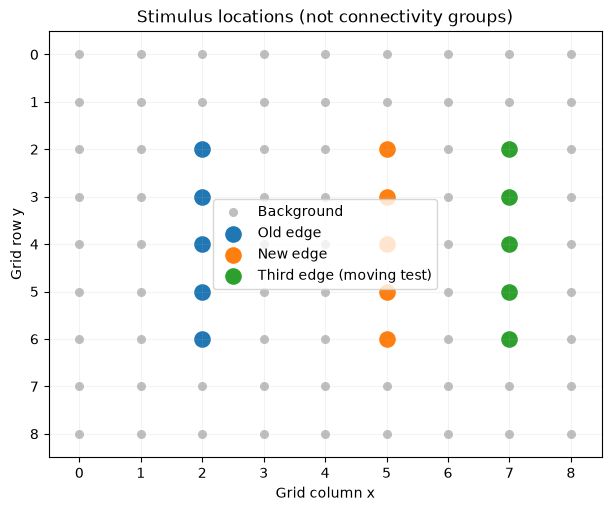

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import brian2 as b2

b2.prefs.codegen.target = "numpy"
width = height = 9
n = width * height
xy = np.column_stack(np.unravel_index(np.arange(n), (height, width)))[..., ::-1]  # (x, y)
rows = np.arange(2, 7)
edge = lambda column: rows * width + column
old, new, third = edge(2), edge(5), edge(7)
all_edge_pixels = np.unique(np.r_[old, new, third])

# Exact same LIF parameters as notebook 17.
tm, tx, te, ti = 10., 3., 5., 12.  # ms
self_weight, threshold = 8., 1.
duration_ms = 130.
dt_ms = 0.05
sigma_e, sigma_i = 0.9, 2.5
radius_e, radius_i = 1.5, 4.5

fig, ax = plt.subplots(figsize=(6, 5), constrained_layout=True)
ax.scatter(xy[:, 0], xy[:, 1], s=30, color="0.75", label="Background")
for ids, color, label in [(old, "tab:blue", "Old edge"),
                          (new, "tab:orange", "New edge"),
                          (third, "tab:green", "Third edge (moving test)")]:
    ax.scatter(xy[ids, 0], xy[ids, 1], s=120, color=color, label=label)
ax.set(xlim=(-0.5, width-0.5), ylim=(height-0.5, -0.5),
       xticks=np.arange(width), yticks=np.arange(height),
       xlabel="Grid column x", ylabel="Grid row y",
       title="Stimulus locations (not connectivity groups)")
ax.grid(alpha=0.15)
ax.legend()
plt.show()

## 2. Implement a single homogeneous recurrent grid

The only conditional changes to connectivity are spatial: whether inhibition covers every neighbor or excludes the closest neighbors, and whether local excitation is included. There are **no indices referring to `old`, `new`, or `third` in synapse construction**.

Synchronous stimulation uses three camera events per target pixel, at \(t=2,4,6\) ms for the old edge and \(t=40,42,44\) ms for the new edge. For the asynchronous test, each row is deterministically shifted by a different small amount. This represents timing variability without a random-search confound.

The clocked Brian2 model uses exact subthreshold integration. Spike transmission and threshold crossing remain clocked, so outcome stability must be checked under timestep refinement.


In [2]:
def simulate(protocol, beta=14., g_i=0.3, g_e=0., surround=False,
             asynchronous=False, dt=dt_ms):
    b2.start_scope()
    b2.defaultclock.dt = dt * b2.ms

    # The protocol controls only external events, never spatial synapses.
    schedule = []
    if protocol in ("old_only", "replacement", "simultaneous", "moving"):
        schedule.append((old, (2., 4., 6.)))
    if protocol in ("new_only", "replacement", "moving"):
        schedule.append((new, (40., 42., 44.)))
    if protocol == "simultaneous":
        schedule.append((new, (2., 4., 6.)))
    if protocol == "moving":
        schedule.append((third, (80., 82., 84.)))

    ids, times = [], []
    for pixels, pulses in schedule:
        for pulse in pulses:
            for j, i in enumerate(pixels):
                offset = (j % 5) * 0.25 if asynchronous else 0.
                ids.append(int(i))
                times.append(pulse + offset)
    order = np.argsort(times, kind="stable")
    camera = b2.SpikeGeneratorGroup(
        n, np.asarray(ids, dtype=int)[order],
        np.asarray(times, dtype=float)[order] * b2.ms)

    parameters = dict(tau_m=tm*b2.ms, tau_ext=tx*b2.ms,
                      tau_exc=te*b2.ms, tau_inh=ti*b2.ms,
                      v_threshold=threshold, self_gain=self_weight,
                      camera_gain=beta)
    neurons = b2.NeuronGroup(n, """
        dv/dt = (-v + Iext + Iexc - Iinh)/tau_m : 1
        dIext/dt = -Iext/tau_ext : 1
        dIexc/dt = -Iexc/tau_exc : 1
        dIinh/dt = -Iinh/tau_inh : 1
    """, threshold="v > v_threshold", reset="v = 0",
        method="exact", namespace=parameters)
    neurons.v = neurons.Iext = neurons.Iexc = neurons.Iinh = 0

    feed = b2.Synapses(camera, neurons, on_pre="Iext_post += camera_gain",
                       namespace=parameters)
    feed.connect(j="i")
    autapse = b2.Synapses(neurons, neurons,
                          on_pre="Iexc_post = self_gain", namespace=parameters)
    autapse.connect(i=np.arange(n), j=np.arange(n))
    objects = [camera, neurons, feed, autapse]

    distances = np.linalg.norm(xy[:, None, :] - xy[None, :, :], axis=-1)
    # distances[post, pre], so the row is the postsynaptic cell.
    if g_i > 0:
        min_radius = 1.5 if surround else 0.
        post, pre = np.where((distances > min_radius) &
                             (distances <= radius_i))
        weights = g_i * np.exp(-distances[post, pre]**2/(2*sigma_i**2))
        lateral_inh = b2.Synapses(neurons, neurons, "w : 1",
                                 on_pre="Iinh_post += w")
        lateral_inh.connect(i=pre, j=post)
        lateral_inh.w = weights
        objects.append(lateral_inh)
    if g_e > 0:
        post, pre = np.where((distances > 0) & (distances <= radius_e))
        weights = g_e * np.exp(-distances[post, pre]**2/(2*sigma_e**2))
        lateral_exc = b2.Synapses(neurons, neurons, "w : 1",
                                 on_pre="Iexc_post += w")
        lateral_exc.connect(i=pre, j=post)
        lateral_exc.w = weights
        objects.append(lateral_exc)

    spike_monitor = b2.SpikeMonitor(neurons)
    objects.append(spike_monitor)
    b2.Network(*objects).run(duration_ms*b2.ms)
    return dict(t=np.asarray(spike_monitor.t/b2.ms),
                i=np.asarray(spike_monitor.i, dtype=int))


def counts(run, pixels, left, right):
    return np.array([np.count_nonzero((run["i"] == i) &
                     (run["t"] >= left) & (run["t"] < right))
                     for i in pixels], dtype=int)


def evaluate(beta, g_i, g_e=0., surround=False, asynchronous=False, dt=dt_ms):
    cfg = dict(beta=beta, g_i=g_i, g_e=g_e, surround=surround,
               asynchronous=asynchronous, dt=dt)
    runs = {name: simulate(name, **cfg)
            for name in ("old_only", "new_only", "replacement")}
    # Each pixel must fire at least twice in each of two disjoint late windows.
    old_ctrl = [counts(runs["old_only"], old, a, b)
                for a, b in ((90., 105.), (105., 120.))]
    new_ctrl = [counts(runs["new_only"], new, a, b)
                for a, b in ((90., 105.), (105., 120.))]
    old_repl = [counts(runs["replacement"], old, a, b)
                for a, b in ((90., 105.), (105., 120.))]
    new_repl = [counts(runs["replacement"], new, a, b)
                for a, b in ((90., 105.), (105., 120.))]
    background = np.setdiff1d(np.arange(n), np.r_[old, new])
    background_repl = [counts(runs["replacement"], background, a, b)
                       for a, b in ((90., 105.), (105., 120.))]
    active = lambda x: np.logical_and(x[0] >= 2, x[1] >= 2)
    silent = lambda x: np.logical_and(x[0] == 0, x[1] == 0)
    stable_old = active(old_ctrl)
    stable_new = active(new_ctrl)
    removed_old = silent(old_repl)
    stable_replacement = active(new_repl)
    quiet_background = silent(background_repl)
    success = (stable_old.all() and stable_new.all() and removed_old.all()
               and stable_replacement.all() and quiet_background.all())
    return dict(**cfg, old_control=int(stable_old.sum()),
                new_control=int(stable_new.sum()),
                old_silent=int(removed_old.sum()),
                new_persistent=int(stable_replacement.sum()),
                off_target=int((~quiet_background).sum()),
                success=bool(success))

## 3. First test: does the unlabelled graph preserve the successful mechanism?

Start at the two-population operating point (input strength 14, inhibition 0.5). Because notebook 17 **normalized inhibitory weights over only the opposite edge**, these are *not* numerically equivalent couplings. Test a small range of unnormalized spatial weights around that scale. A failed configuration is not repaired by relabeling neurons or hardcoding the two target edges.

Two architectures are compared at this stage: broad inhibition and surround inhibition. For the first pass we hold local excitation at zero, so any difference reflects the inhibitory geometry alone. A zero-inhibition control checks that the old edge cannot disappear through an unmodeled mechanism.


In [3]:
scan = []
for surround in tqdm((False, True), desc="Spatial inhibition architecture"):
    for g_i in (0., 0.1, 0.25, 0.5):
        for beta in (14., 22.):
            scan.append(evaluate(beta=beta, g_i=g_i, surround=surround))
summary = pd.DataFrame(scan)
display(summary.sort_values(["success", "new_persistent", "old_silent"],
                            ascending=False))
print(f"Strictly successful configurations: {summary.success.sum()}/{len(summary)}")
assert (summary.loc[summary.g_i == 0, "old_silent"] == 0).all(), (
    "Unexpected loss of old activity without inhibition")

Spatial inhibition architecture:   0%|          | 0/2 [00:00<?, ?it/s]WARNING    'i' is an internal variable of group 'synapses', but also exists in the run namespace with the value np.int64(56). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'i' is an internal variable of group 'synapses', but also exists in the run namespace with the value np.int64(59). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
Spatial inhibition architecture: 100%|██████████| 2/2 [00:12<00:00,  6.38s/it]


,beta,g_i,g_e,surround,asynchronous,dt,old_control,new_control,old_silent,new_persistent,off_target,success
11,22.0,0.10,0.0,True,False,0.05,5,5,5,5,0,True
10,14.0,0.10,0.0,True,False,0.05,5,5,3,5,0,False
0,14.0,0.00,0.0,False,False,0.05,5,5,0,5,0,False
1,22.0,0.00,0.0,False,False,0.05,5,5,0,5,0,False
8,14.0,0.00,0.0,True,False,0.05,5,5,0,5,0,False
9,22.0,0.00,0.0,True,False,0.05,5,5,0,5,0,False
12,14.0,0.25,0.0,True,False,0.05,3,3,5,4,0,False
2,14.0,0.10,0.0,False,False,0.05,5,5,3,4,0,False
3,22.0,0.10,0.0,False,False,0.05,4,4,5,2,0,False
4,14.0,0.25,0.0,False,False,0.05,0,0,5,2,0,False


Strictly successful configurations: 1/16


## 4. Add local cooperation only if needed

Local recurrent excitation was not consistently helpful in notebook 17. We therefore treat it as a separate controlled change rather than assuming it must help. Select only the most promising inhibition-only configurations according to the **prespecified** success components, then test an additional small positive local excitation weight.

**Avoid circular evaluation:** the asynchronous and moving-edge protocols below remain held out from this selection. Report failure if none of the synchronous configurations succeeds; do not reinterpret partial metrics as success.


In [4]:
ranking = summary.sort_values(["success", "new_persistent", "old_silent",
                               "old_control", "new_control", "off_target"],
                              ascending=[False, False, False, False, False, True])
shortlist = ranking.drop_duplicates(["surround", "beta"]).head(4)
cooperative = []
for row in tqdm(shortlist.itertuples(index=False), total=len(shortlist),
                desc="Local excitation controls"):
    for g_e in (0.15, 0.35):
        cooperative.append(evaluate(beta=row.beta, g_i=row.g_i,
                                    g_e=g_e, surround=row.surround))
cooperation_results = pd.DataFrame(cooperative)
all_results = pd.concat([summary, cooperation_results], ignore_index=True)
display(all_results.sort_values(["success", "new_persistent", "old_silent"],
                                ascending=False).head(16))
print("Fully successful configurations:", int(all_results.success.sum()))

Local excitation controls: 100%|██████████| 4/4 [00:05<00:00,  1.48s/it]


,beta,g_i,g_e,surround,asynchronous,dt,old_control,new_control,old_silent,new_persistent,off_target,success
11,22.0,0.10,0.00,True,False,0.05,5,5,5,5,0,True
16,22.0,0.10,0.15,True,False,0.05,5,5,5,5,0,True
17,22.0,0.10,0.35,True,False,0.05,5,5,5,5,4,False
10,14.0,0.10,0.00,True,False,0.05,5,5,3,5,0,False
18,14.0,0.10,0.15,True,False,0.05,5,5,1,5,0,False
0,14.0,0.00,0.00,False,False,0.05,5,5,0,5,0,False
1,22.0,0.00,0.00,False,False,0.05,5,5,0,5,0,False
8,14.0,0.00,0.00,True,False,0.05,5,5,0,5,0,False
9,22.0,0.00,0.00,True,False,0.05,5,5,0,5,0,False
19,14.0,0.10,0.35,True,False,0.05,5,5,0,5,0,False


Fully successful configurations: 2


## 5. Visualize what survives and where it survives

A result may have five active new-edge pixels but also many spurious persistent pixels. To avoid this false positive, inspect the **entire grid** during the late evaluation window. Plots show spikes per neuron during 90–120 ms and a raster for the matched old-only and replacement runs. The selected configuration is the top result in the synchronous scan; its choice does not use held-out protocols.


Selected synchronous configuration: {'beta': 22.0, 'g_i': 0.1, 'g_e': 0.0, 'surround': True}
old_control          5
new_control          5
old_silent           5
new_persistent       5
off_target           0
success           True


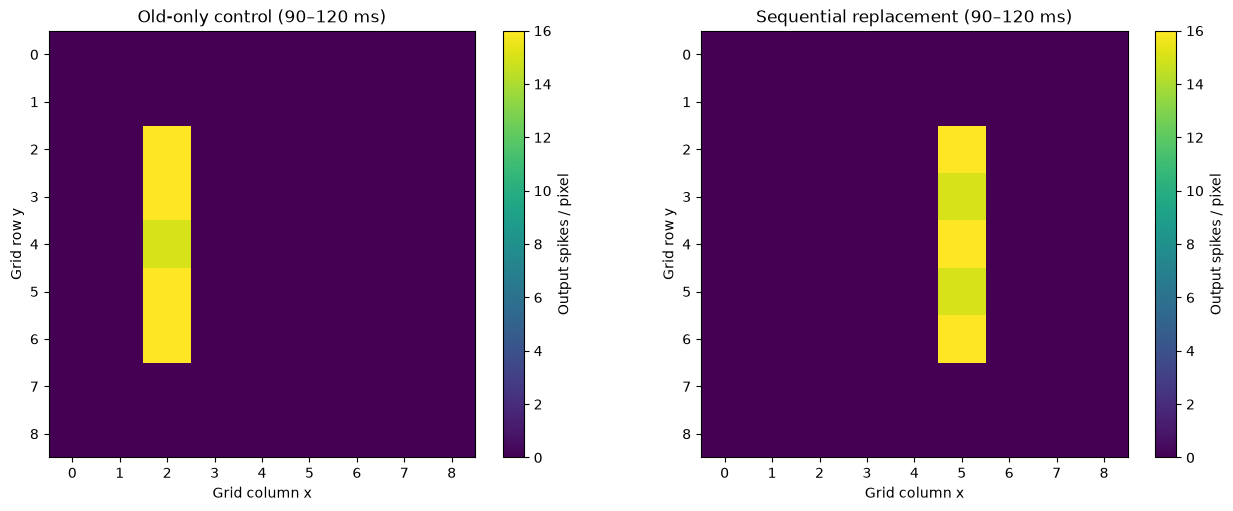

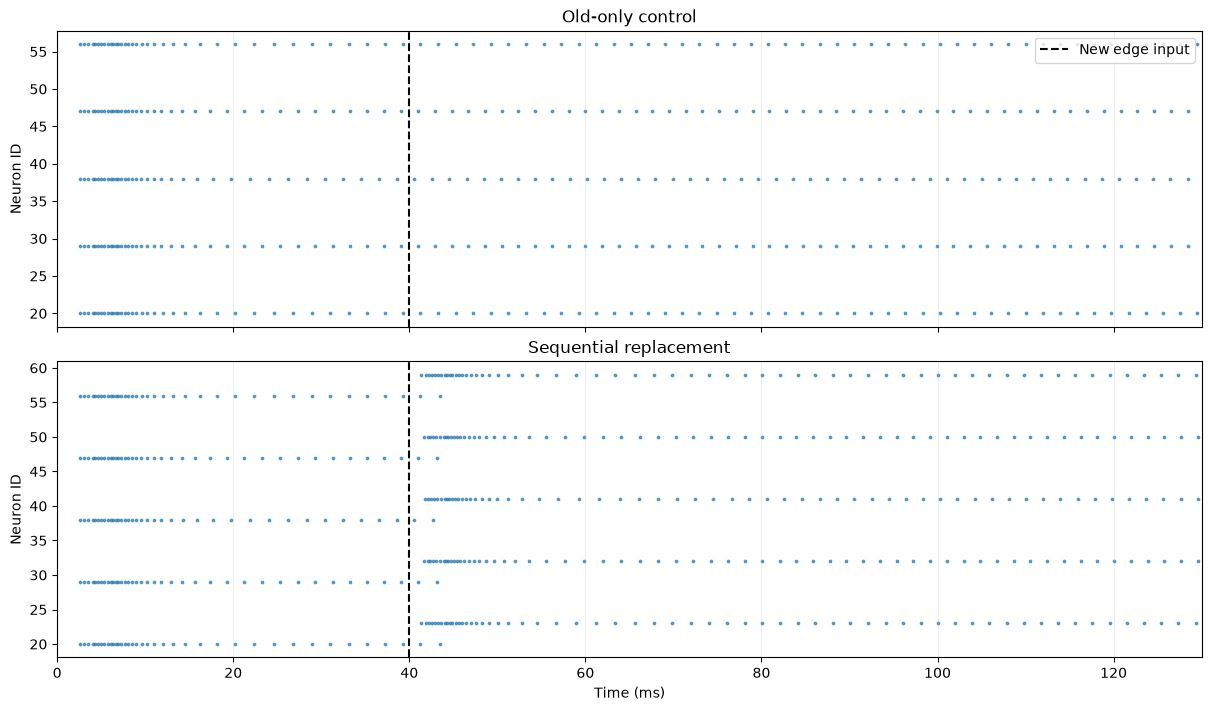

In [5]:
ranked = all_results.sort_values(["success", "new_persistent", "old_silent",
                                   "old_control", "new_control", "off_target"],
                                  ascending=[False, False, False, False, False, True])
best = ranked.iloc[0]
chosen = dict(beta=float(best.beta), g_i=float(best.g_i),
              g_e=float(best.g_e), surround=bool(best.surround))
print("Selected synchronous configuration:", chosen)
print(best[["old_control", "new_control", "old_silent", "new_persistent",
            "off_target", "success"]].to_string())
old_run = simulate("old_only", **chosen)
replacement_run = simulate("replacement", **chosen)
fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
for ax, (name, run) in zip(axes, (("Old-only control", old_run),
                                 ("Sequential replacement", replacement_run))):
    late = run["i"][(run["t"] >= 90) & (run["t"] < 120)]
    image = np.bincount(late, minlength=n).reshape(height, width)
    im = ax.imshow(image, cmap="viridis", origin="upper", vmin=0)
    ax.set(title=name + " (90–120 ms)", xlabel="Grid column x", ylabel="Grid row y")
    ax.set_xticks(np.arange(width)); ax.set_yticks(np.arange(height))
    fig.colorbar(im, ax=ax, label="Output spikes / pixel")
plt.show()

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, constrained_layout=True)
for ax, (name, run) in zip(axes, (("Old-only control", old_run),
                                 ("Sequential replacement", replacement_run))):
    ax.scatter(run["t"], run["i"], s=3, alpha=0.65)
    ax.axvline(40, color="black", linestyle="--", label="New edge input")
    ax.set(ylabel="Neuron ID", title=name)
    ax.grid(axis="x", alpha=0.2)
axes[-1].set(xlabel="Time (ms)", xlim=(0, duration_ms))
axes[0].legend()
plt.show()

## 6. Held-out event timing and spatial challenges

### Asynchronous events

Each row of an edge receives input at a slightly different time. We compare the same chosen network at synchronous and asynchronous timings without retuning parameters.

### Simultaneous edges

A network that immediately suppresses all but one pixel is not a useful edge representation. Report how many pixels in each edge fire repeatedly after a simultaneous stimulus, and how many unrelated pixels become active. **We do not demand that both competing edges persist indefinitely**, but the result reveals whether the circuit is too winner-take-all.

### Moving edge

An additional five-pixel edge is stimulated at 80–84 ms at column 7. Its final activity is assessed in [110,125) ms and the previously active old/new edges are assessed in the same window. This is deliberately harder than the two-edge replacement protocol and is not used for model selection.


Asynchronous, selected configuration:


,beta,g_i,g_e,surround,asynchronous,dt,old_control,new_control,old_silent,new_persistent,off_target,success
0,22.0,0.1,0.0,True,True,0.05,5,5,5,5,0,True


WARNING    'i' is an internal variable of group 'synapses', but also exists in the run namespace with the value np.int64(61). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]



Simultaneous activity in [90, 120) ms
  Old edge: per-pixel spikes [16, 0, 0, 0, 16]
  New edge: per-pixel spikes [16, 0, 0, 0, 16]
  Third edge: per-pixel spikes [0, 0, 0, 0, 0]
  Off-edge spikes: 0

Moving activity in [110, 125) ms
  Old edge: per-pixel spikes [0, 0, 0, 0, 0]
  New edge: per-pixel spikes [0, 0, 0, 0, 0]
  Third edge: per-pixel spikes [8, 7, 7, 7, 8]
  Off-edge spikes: 0


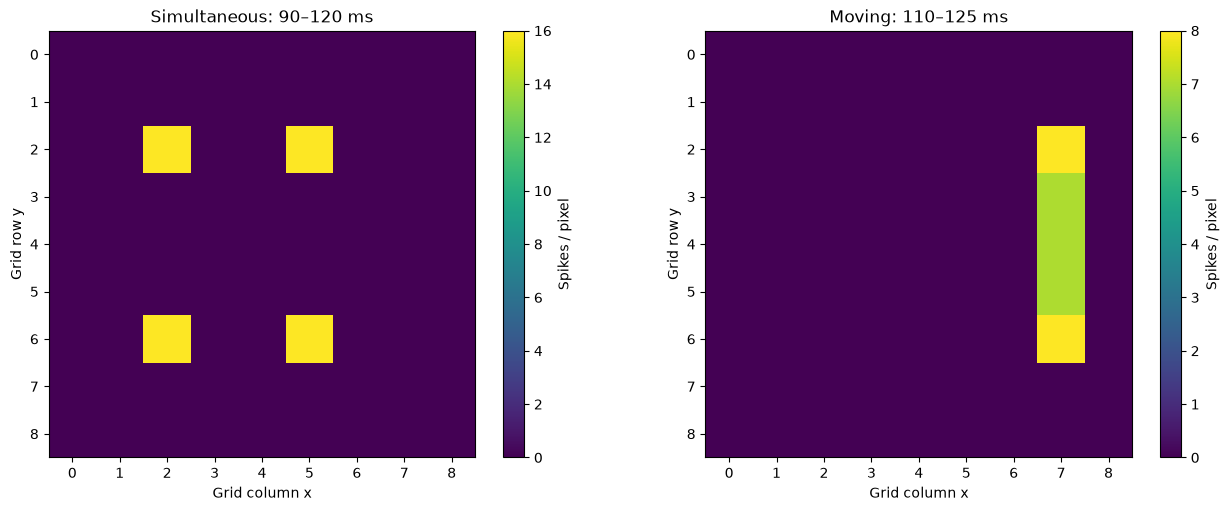

In [6]:
heldout = evaluate(**chosen, asynchronous=True)
print("Asynchronous, selected configuration:")
display(pd.DataFrame([heldout]))

simultaneous = simulate("simultaneous", **chosen)
moving = simulate("moving", **chosen)
for name, run, interval in [("Simultaneous", simultaneous, (90, 120)),
                            ("Moving", moving, (110, 125))]:
    print(f"\n{name} activity in [{interval[0]}, {interval[1]}) ms")
    for label, pixels in [("Old edge", old), ("New edge", new),
                          ("Third edge", third)]:
        print(f"  {label}: per-pixel spikes {counts(run, pixels, *interval).tolist()}")
    other = np.setdiff1d(np.arange(n), all_edge_pixels)
    print("  Off-edge spikes:", counts(run, other, *interval).sum())

fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
for ax, (name, run, left, right) in zip(axes, (("Simultaneous", simultaneous, 90, 120),
                                         ("Moving", moving, 110, 125))):
    late = run["i"][(run["t"] >= left) & (run["t"] < right)]
    im = ax.imshow(np.bincount(late, minlength=n).reshape(height, width),
                   cmap="viridis", origin="upper")
    ax.set(title=f"{name}: {left}–{right} ms", xlabel="Grid column x",
           ylabel="Grid row y")
    fig.colorbar(im, ax=ax, label="Spikes / pixel")
plt.show()

## 7. Numerical refinement and interpretation

Repeat the selected synchronous configuration at 0.1, 0.05 and 0.025 ms. The evaluation uses identical stimulus times (multiples of 0.25 ms) at all three resolutions. **Agreement in the classification metrics supports only finite protocol robustness**, not exact spike-time convergence.

**Interpretation hierarchy:**

- If strict success holds for the global spatial rule, the predefined populations from notebook 17 were unnecessary for this *specific* fixed-edge task.
- If the old/new pixels meet the criterion but off-target pixels persist, the network has a spatial selectivity problem, not clean replacement.
- If synchronous success disappears for asynchronous input, it is an event-timing fragility.
- If moving-edge replacement fails, the circuit does not yet generalize to more than two successive locations.
- If no configuration succeeds, the failure demonstrates a limitation of this **bounded test range**, not an impossibility theorem for spatial inhibition.

The next research decision should follow these observations. Do **not** add adaptation, depression or a gate merely to make the results look positive.


In [7]:
refinement = []
for dt in tqdm((0.1, 0.05, 0.025), desc="Timestep refinement"):
    refinement.append(evaluate(**chosen, dt=dt))
display(pd.DataFrame(refinement))
print("Notebook complete. Compare held-out and refinement results before drawing conclusions.")

Timestep refinement: 100%|██████████| 3/3 [00:02<00:00,  1.29it/s]


,beta,g_i,g_e,surround,asynchronous,dt,old_control,new_control,old_silent,new_persistent,off_target,success
0,22.0,0.1,0.0,True,False,0.100,5,5,5,5,0,True
1,22.0,0.1,0.0,True,False,0.050,5,5,5,5,0,True
2,22.0,0.1,0.0,True,False,0.025,5,5,5,5,0,True


Notebook complete. Compare held-out and refinement results before drawing conclusions.
